In [95]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sci
import sympy as sp
t = np.linspace(0,15,1000)

In [96]:
m = 1
wn=1
xi=sp.sqrt(2)
dx0=0
x0=1
def f(t):
    return np.sin(t)
def F(s, w):
    return w/(s**2+w**2)

In [97]:
# calcolo k e c
k = m * wn**2
c = xi * 2 * m * wn
print("k=",k)
print("c=",c)

k= 1
c= 2*sqrt(2)


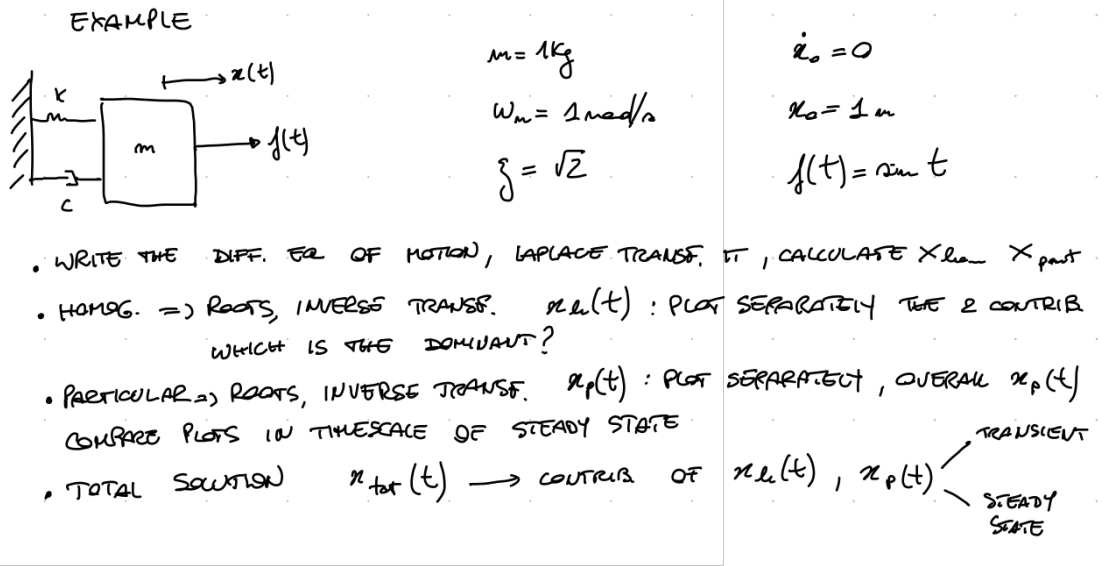

# 1.1 Write the diff. equation
$$
k x + c \dot x + m \ddot x = f(t)
$$
# 1.2 Laplace transform it
$$
X(s)=\frac{-c+ms}{k+cs+ms^2}+\frac{1}{k+cs+ms^2}*F(s)
$$
# 1.3 Calculate $X_{hom}$ and $X_{part}$
$$
\begin{matrix}
X_h = \frac{s-c/m}{s^2+2*\xi*\omega_n*s+\omega_n^2} \\
\\
X_p = \frac{1}{s^2+2*\xi*\omega_n*s+\omega_n^2}
\end{matrix}
$$

# 2.1 $X_{hom}$ roots $=$ poles
We are in an overdamped system, therefore we expect pure real poles.

In [98]:
s = sp.symbols("s")
den = s**2+2*xi*wn*s+wn**2
p1, p2 = sp.solve(den, s)
print("p1=",p1,"\np2=",p2)
p1_f = float(p1)
p2_f = float(p2)

p1= 1 - sqrt(2) 
p2= -sqrt(2) - 1


# 2.2 Inverse transorm it
For systems with oscillating input we can write:
$$
X(s) = \frac{A(s)}{B(s)} + G(s)M\frac{\omega}{s^2 + \omega^2}
$$
- $A(s)/B(s)=X_h(s)$
- $M = 1$ from the input function $f(t) = M \sin(\omega * t)$
- $G(s) = X_p(s)$

In [99]:
A = s-c/m
B = s**2-2*xi*wn*s+wn**2;

def X_hom(s):
    return (A/((s-p1)*(s-p2)))

R_1h = sp.limit((s-p1)*X_hom(s), s, p1)
print("R_1h=",R_1h,"=",float(R_1h))

R_2h = sp.limit((s-p2)*X_hom(s), s, p2)
print("R_2h=",R_2h, "=",float(R_2h))

R_1h= 1/2 - 3*sqrt(2)/2 = -1.6213203435596426
R_2h= 1/2 + 3*sqrt(2)/2 = 2.6213203435596424


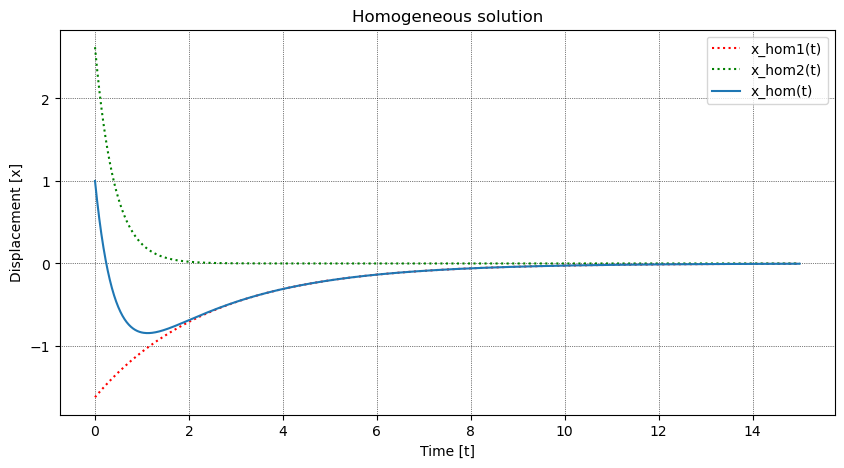

In [100]:
def x_hom(t, R_1h=R_1h, R_2h=R_2h, p1=p1, p2=p2):
    R_1h = float(R_1h)
    R_2h = float(R_2h)
    p1 = float(p1)
    p2 = float(p2)
    ris = R_1h*np.exp(p1*t) + R_2h*np.exp(p2*t)
    return ris
def x_h1(t, R_1h=R_1h, p1=p1):
    R_1h = float(R_1h)
    p1 = float(p1)
    ris = R_1h*np.exp(p1 * t)
    return ris

def x_h2(t, R_2h=R_2h, p2=p2):
    R_2h=float(R_2h)
    p2=float(p2)
    ris=R_2h*np.exp(p2 *t)
    return ris

f_h = plt.figure(clear=True, figsize=(10, 5))
plt.plot(t, x_h1(t), ":r",label="x_hom1(t)")
plt.plot(t, x_h2(t), ":g",label="x_hom2(t)")
plt.plot(t, x_hom(t), label="x_hom(t)")
plt.title("Homogeneous solution")
plt.legend()
plt.xlabel("Time [t]")
plt.ylabel("Displacement [x]")
plt.grid(which="both", color="k", linestyle=":", linewidth=0.5)

# 3.1 Particular roots

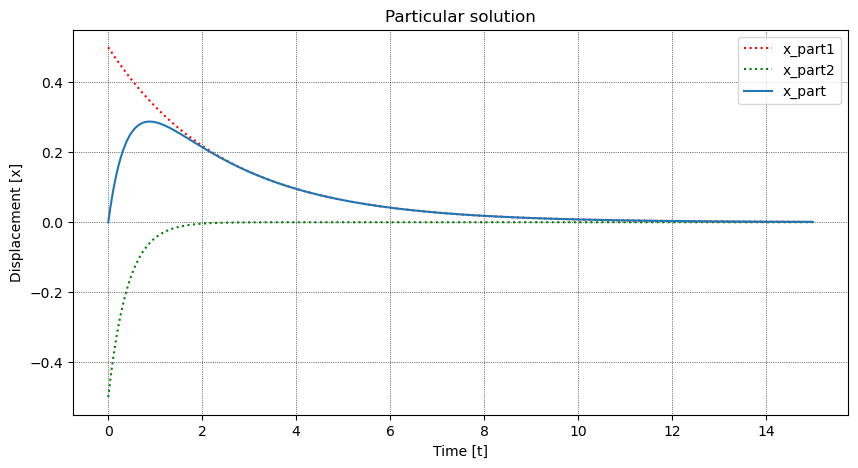

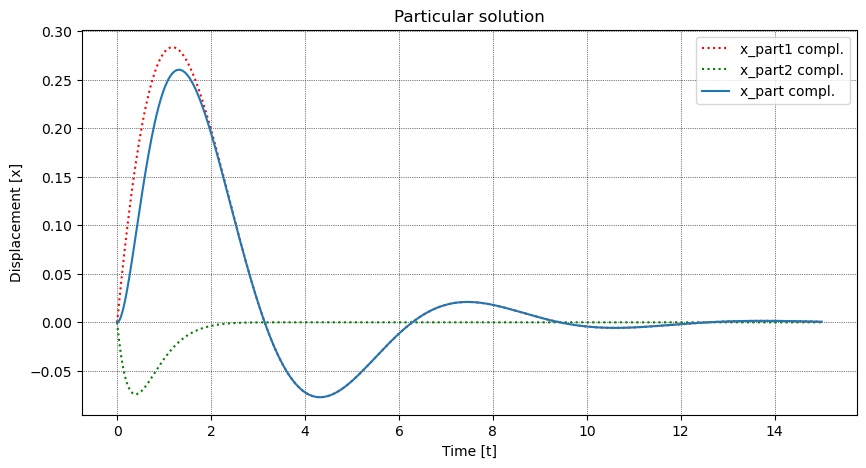

In [101]:
def X_part(s):
    return (1/m)/((s-p1)*(s-p2))#(s**2+2*xi*wn*s+wn**2)

R_1p = sp.limit((s-p1)*X_part(s), s, p1)
#print("R_1p=",R_1p)

R_2p = sp.limit((s-p2)*X_part(s), s, p2)
#print("R_2p=",R_2p)

def x_part(t, R_1p=R_1p, R_2p=R_2p, p1=p1, p2=p2):
    R_1p = float(R_1p)
    R_2p = float(R_2p)
    p1 = float(p1)
    p2 = float(p2)
    ris = R_1p*np.exp(p1*t) + R_2p*np.exp(p2*t)
    return ris

def x_part1(t, R_1p=R_1p, p1=p1):
    R_1p = float(R_1p)
    p1=float(p1)
    ris = R_1p*np.exp(p1*t)
    return ris

def x_part2(t, R_2p=R_2p, p2=p2):
    R_2p = float(R_2p)
    p2=float(p2)
    ris = R_2p*np.exp(p2*t)
    return ris

f_p = plt.figure(clear=True, figsize=(10, 5))
plt.plot(t, x_part1(t), ":r", label="x_part1")
plt.plot(t, x_part2(t), ":g", label="x_part2")
plt.plot(t, x_part(t), label="x_part")
plt.title("Particular solution")
plt.legend()
plt.xlabel("Time [t]")
plt.ylabel("Displacement [x]")
plt.grid("axis=bott", which="both", color="k", linestyle=":", linewidth=0.5)

f_pc = plt.figure(clear = True, figsize=(10,5))
plt.plot(t, x_part1(t)*f(t), ":r", label="x_part1 compl.")
plt.plot(t, x_part2(t)*f(t), ":g", label="x_part2 compl.")
plt.plot(t, x_part(t)*f(t), label="x_part compl.")
plt.title("Particular solution")
plt.legend()
plt.xlabel("Time [t]")
plt.ylabel("Displacement [x]")
plt.grid("axis=bott", which="both", color="k", linestyle=":", linewidth=0.5)

# $p_1$ or $p_2$ dominant?
The pole with $|p_i|$ smaller dominates becouse goes to zero slower.

# total $x(t)$
both for steady state and not

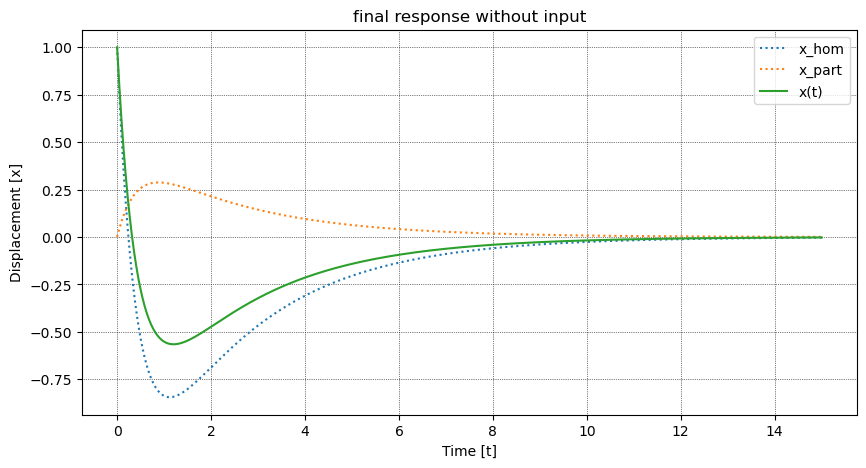

In [104]:
f_tot = plt.figure(figsize=(10,5))
plt.plot(t, x_hom(t), ":", label="x_hom")
plt.plot(t, x_part(t), ":",label="x_part")
plt.plot(t, x_hom(t)+x_part(t), label="x(t)")
plt.legend()
plt.grid(":",axis="both", which="both")
plt.title("final response without input")
plt.xlabel("Time [t]")
plt.ylabel("Displacement [x]")
plt.grid("axis=bott", which="both", color="k", linestyle=":", linewidth=0.5)

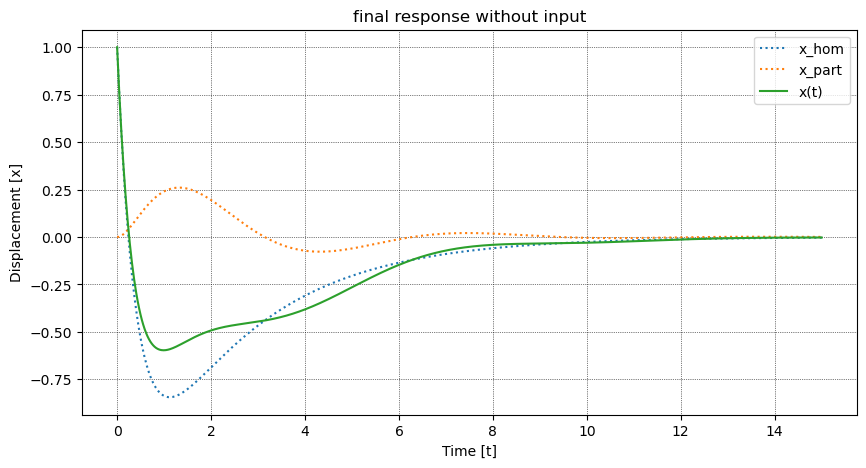

In [105]:
f_tot = plt.figure(figsize=(10,5))
plt.plot(t, x_hom(t), ":", label="x_hom")
plt.plot(t, x_part(t)*f(t), ":",label="x_part")
plt.plot(t, x_hom(t)+x_part(t)*f(t), label="x(t)")
plt.legend()
plt.grid(":",axis="both", which="both")
plt.title("final response without input")
plt.xlabel("Time [t]")
plt.ylabel("Displacement [x]")
plt.grid("axis=bott", which="both", color="k", linestyle=":", linewidth=0.5)